In [ ]:
import os
os.chdir(os.path.expandvars("/scratch/vp91/$USER/intro-to-cuda"))

# Asynchronous CUDA Calls


> **Overview**
>
> 
>  * **Time:** 60 min
> 
>  1. Learn how to use asynchronous CUDA APIs to improve performance.
>  1. Understand the concept of CUDA streams and how they can be used to overlap memory transfers and kernel execution.

This section provides an example of how to use asynchronous CUDA APIs to improve the performance of a simple vector addition program.
By using CUDA streams, we can overlap memory transfers and kernel execution, leading to better GPU utilization.

## CUDA Streams


A stream is a sequence of operations that execute on the GPU in the order they are issued. Streams allow for concurrent execution of multiple operations, such
as memory transfers and kernel launches, which can significantly improve performance by overlapping computation and data transfer.

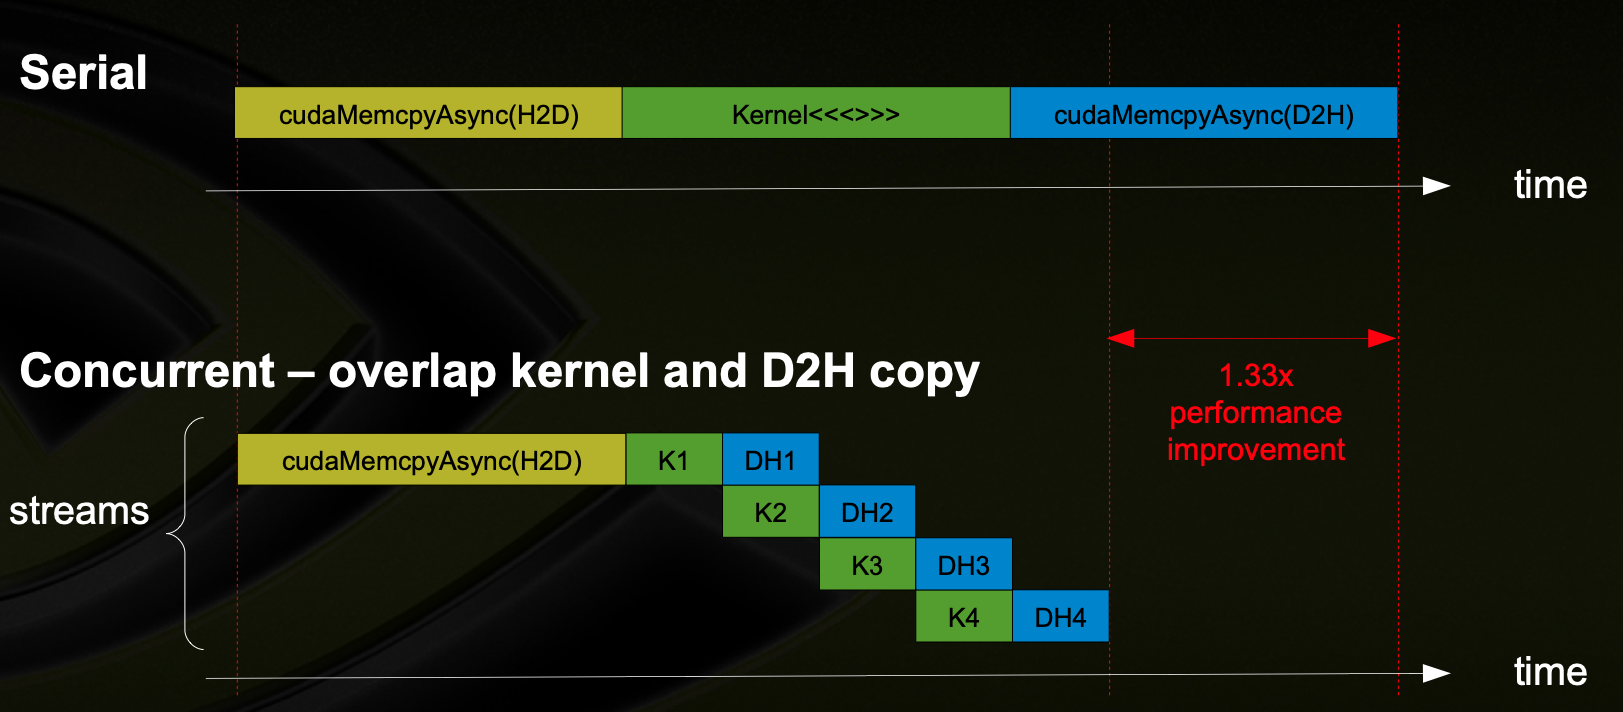

Streams are particularly useful in scenarios where you want to perform multiple operations on the GPU without waiting for each operation to complete before
starting the next one. By using streams, you can maximize the utilization of the GPU and reduce idle time.

## Why streams result in more concurrency?


1. Streaming Multiprocessors (SMs)

    * GPUs contain multiple Streaming Multiprocessors (SMs).
    * Each SM can execute threads from different kernels concurrently, as long as there's enough space and resources (registers, shared memory, etc.).
    * So parallel kernel launches can utilize multiple SMs, allowing for more threads to be executed simultaneously.

2. Separate Engines for Compute and Memory Operations

    * GPUs have separate engines for memory operations (like `cudaMemcpyAsync`) and compute operations (like kernel launches).
    * This means that while one stream is executing a kernel, another stream can perform memory transfers without waiting for the first to finish.
    * This overlap allows for better utilization of the GPU's resources.


For efficient and proper use of streams, it's important to ensure that

* The GPU must support concurrent kernel execution.
* There must be no resource conflict (e.g., using different memory regions).
* Streams must be independent — no implicit synchronization (e.g., from using the default stream).


> **Important**
>
> Streams are not a replacement for parallelism; they are a way to manage concurrency on the GPU. You can have multiple streams executing concurrently, 
> but each stream's operations will still be executed in order.

## Main differences from the synchronous version


* Create and use a CUDA stream with `cudaStreamCreate()`.
* Use `cudaMemcpyAsync()` for asynchronous memory copies.
* Launch the kernel in the created stream.
* Synchronize the stream with `cudaStreamSynchronize()` to wait for completion.
* Cleanup the stream after use.



> **Important**
>
> `cudaMalloc` and `cudaFree` are still synchronous operations, meaning they block the host until the memory allocation or deallocation is complete.

```cpp
#include <stdio.h>
#include <cuda_runtime.h>

// Kernel 1: Adds 1 to each element
__global__ void kernel1(float* data, int n) 
{
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < n)
        data[idx] += 1.0f;
}

// Kernel 2: Multiplies each element by 2
__global__ void kernel2(float* data, int n) 
{
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < n)
        data[idx] *= 2.0f;
}

int main() 
{
    const int n1 = 512;
    const int n2 = 512;
    const int size1 = n1 * sizeof(float);
    const int size2 = n2 * sizeof(float);

    float *h_data1 = (float*)malloc(size1);
    float *h_data2 = (float*)malloc(size2);

    // Initialize host data
    for (int i = 0; i < n1; i++) h_data1[i] = i;
    for (int i = 0; i < n2; i++) h_data2[i] = i * 10;

    float *d_data1, *d_data2;
    cudaMalloc(&d_data1, size1);
    cudaMalloc(&d_data2, size2);

    cudaStream_t stream1, stream2;
    cudaStreamCreate(&stream1);
    cudaStreamCreate(&stream2);

    // Copy and launch kernel on stream1
    cudaMemcpyAsync(d_data1, h_data1, size1, cudaMemcpyHostToDevice, stream1);
    int threads = 256;
    int blocks1 = (n1 + threads - 1) / threads;
    kernel1<<<blocks1, threads, 0, stream1>>>(d_data1, n1);

    // Copy and launch kernel on stream2
    cudaMemcpyAsync(d_data2, h_data2, size2, cudaMemcpyHostToDevice, stream2);
    int blocks2 = (n2 + threads - 1) / threads;
    kernel2<<<blocks2, threads, 0, stream2>>>(d_data2, n2);

    // Copy results back asynchronously
    cudaMemcpyAsync(h_data1, d_data1, size1, cudaMemcpyDeviceToHost, stream1);
    cudaMemcpyAsync(h_data2, d_data2, size2, cudaMemcpyDeviceToHost, stream2);

    // Wait for streams to finish
    cudaStreamSynchronize(stream1);
    cudaStreamSynchronize(stream2);

    // Print some results
    printf("Stream 1 results:\n");
    for (int i = 0; i < 5; i++) printf("h_data1[%d] = %f\n", i, h_data1[i]);

    printf("Stream 2 results:\n");
    for (int i = 0; i < 5; i++) printf("h_data2[%d] = %f\n", i, h_data2[i]);

    // Cleanup
    cudaStreamDestroy(stream1);
    cudaStreamDestroy(stream2);
    cudaFree(d_data1);
    cudaFree(d_data2);
    free(h_data1);
    free(h_data2);

    return 0;
}
```

| API | Purpose |
| --- | --- |
| `cudaMemcpyAsync` | Starts a memory copy asynchronously and returns immediately. |
| `cudaStream_t` | Represents a CUDA stream (a queue of commands executed in order). |
| `cudaStreamCreate()` | Creates a new CUDA stream. |
| `cudaStreamSynchronize()` | Blocks host until all commands in the stream have completed. |
| `cudaStreamDestroy()` | Destroys the CUDA stream and frees associated resources. |

> **Key Points**
>
> 
>  1. Asynchronous CUDA APIs allow overlapping memory transfers and kernel execution.
>  1. CUDA streams enable concurrent execution of multiple tasks on the GPU.
>  1. Proper synchronization is crucial to ensure data integrity and correctness.
>  1. Cleanup of streams and device memory is necessary to avoid resource leaks.

## Run the tutorial example

Use a notebook kernel on an allocated GPU node with CUDA loaded and `nvcc` available. The following cells write the tutorial's two-stream program, compile it, and run it. Generated files are stored in `asynchronous_output/`.

In [ ]:
from pathlib import Path

Path("asynchronous_output").mkdir(exist_ok=True)

In [ ]:
%%writefile asynchronous_output/two_streams.cu
#include <stdio.h>
#include <cuda_runtime.h>

// Kernel 1: Adds 1 to each element
__global__ void kernel1(float* data, int n) 
{
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < n)
        data[idx] += 1.0f;
}

// Kernel 2: Multiplies each element by 2
__global__ void kernel2(float* data, int n) 
{
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < n)
        data[idx] *= 2.0f;
}

int main() 
{
    const int n1 = 512;
    const int n2 = 512;
    const int size1 = n1 * sizeof(float);
    const int size2 = n2 * sizeof(float);

    float *h_data1 = (float*)malloc(size1);
    float *h_data2 = (float*)malloc(size2);

    // Initialize host data
    for (int i = 0; i < n1; i++) h_data1[i] = i;
    for (int i = 0; i < n2; i++) h_data2[i] = i * 10;

    float *d_data1, *d_data2;
    cudaMalloc(&d_data1, size1);
    cudaMalloc(&d_data2, size2);

    cudaStream_t stream1, stream2;
    cudaStreamCreate(&stream1);
    cudaStreamCreate(&stream2);

    // Copy and launch kernel on stream1
    cudaMemcpyAsync(d_data1, h_data1, size1, cudaMemcpyHostToDevice, stream1);
    int threads = 256;
    int blocks1 = (n1 + threads - 1) / threads;
    kernel1<<<blocks1, threads, 0, stream1>>>(d_data1, n1);

    // Copy and launch kernel on stream2
    cudaMemcpyAsync(d_data2, h_data2, size2, cudaMemcpyHostToDevice, stream2);
    int blocks2 = (n2 + threads - 1) / threads;
    kernel2<<<blocks2, threads, 0, stream2>>>(d_data2, n2);

    // Copy results back asynchronously
    cudaMemcpyAsync(h_data1, d_data1, size1, cudaMemcpyDeviceToHost, stream1);
    cudaMemcpyAsync(h_data2, d_data2, size2, cudaMemcpyDeviceToHost, stream2);

    // Wait for streams to finish
    cudaStreamSynchronize(stream1);
    cudaStreamSynchronize(stream2);

    // Print some results
    printf("Stream 1 results:\n");
    for (int i = 0; i < 5; i++) printf("h_data1[%d] = %f\n", i, h_data1[i]);

    printf("Stream 2 results:\n");
    for (int i = 0; i < 5; i++) printf("h_data2[%d] = %f\n", i, h_data2[i]);

    // Cleanup
    cudaStreamDestroy(stream1);
    cudaStreamDestroy(stream2);
    cudaFree(d_data1);
    cudaFree(d_data2);
    free(h_data1);
    free(h_data2);

    return 0;
}

In [ ]:
!nvcc -O2 asynchronous_output/two_streams.cu -o asynchronous_output/two_streams

In [ ]:
!./asynchronous_output/two_streams

The first five values should be:

- Stream 1: `1, 2, 3, 4, 5` (each input increased by one).
- Stream 2: `0, 20, 40, 60, 80` (each input multiplied by two).

The program waits for both streams before printing or freeing their data.

## Exercise 05: Asynchronous CUDA Calls
**Time: 20 min**

1. Run [vector_add.cu](../exercises/05-asynchronous/vector_add.cu) and check the output.
2. Run [vector_add_async.cu](../exercises/05-asynchronous/vector_add_async.cu) and check the output.
3. What is the performance difference between the two programs?

Use the same allocated GPU for both runs. Both programs perform ten vector additions and check their results. The asynchronous version uses four streams.

### Compile both programs

Executables are saved in `asynchronous_output/`.

In [ ]:
from pathlib import Path

Path("asynchronous_output").mkdir(exist_ok=True)
!nvcc -O2 exercises/05-asynchronous/vector_add.cu -o asynchronous_output/vector_add
!nvcc -O2 exercises/05-asynchronous/vector_add_async.cu -o asynchronous_output/vector_add_async

### Run the synchronous version

Check that every iteration reports success, and record the printed total time.

In [ ]:
!./asynchronous_output/vector_add

### Run the asynchronous version

Check that result verification reports `PASSED`, and record the printed total time. Rerun both execution cells a few times to see how stable the measurements are.

In [ ]:
!./asynchronous_output/vector_add_async

### Compare the results

| Version | Reported total time (ms) | Verification |
| --- | --- | --- |
| Synchronous | | |
| Asynchronous, four streams | | |

Calculate the ratio `synchronous time / asynchronous time`: a value above 1 means the asynchronous program reported a shorter time.

**Read the timing regions before interpreting the ratio.** Both programs use a CPU wall-clock timer around their work, despite labelling the output "GPU time". The synchronous program includes result verification and per-iteration printing inside its timer; the asynchronous program verifies results after stopping its timer. Their buffer allocation strategies also differ. The reported ratio therefore does not isolate the effect of streams.

For a fairer comparison, move synchronous verification and printing outside its timed region, keep the work and timing boundaries equivalent, and repeat the measurements. Do the results still differ?

### Observations

Record correctness, timings, and what could explain the performance difference.